# Métricas de la trivia — Robot Romeo (perfil OPTIMISTA)
**Sesión 11 nov 2026 · perfil optimista (empatía 0.4, base (0.40, 0.30, 0.20)) · captura con `ROMEO_MEDIR=1`**

Solo métricas de la **trivia** (primeras 33 preguntas). Este notebook lee los CSV crudos y genera las gráficas.

**Novedad de esta sesión:** los tiempos de **STT, SER y TER** se miden **por separado en la propia Raspberry**
(archivo `percepcion.csv`), ya no en el PC. Cada turno guarda `t_stt_ms`, `t_ser_ms`, `t_ter_ms` e `ida_vuelta_ms`.

**Nodos del sistema:** `communication_node` (STT+TTS) · `expression_faces_node` (FER+caras) · `moving_control_node` (carrito) · `orchestrator_node` (afectiva PULSE/ROSE/AEB + LLM + trivia).

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 11, "axes.spines.top": False,
    "axes.spines.right": False, "font.family": "DejaVu Sans",
})
GRIS="#2b3a52"; VERDE="#1ba378"; NARANJA="#e07a1a"; AZUL="#2a78d6"; ROJO="#c0392b"; MORADO="#6a5aa0"

BASE = Path(r".")   # misma carpeta del notebook
def ruta(n): return BASE / n
N_PREGUNTAS = 33   # la sesion de trivia: primeras 33 preguntas

## 1. Cargar los datos

In [2]:
# La trivia empieza en la PRIMERA pregunta que hace Romeo (Asistente [emo]: ...?).
import re
INICIO_TRIVIA = 0.0
log = open(ruta("romeo_run.log"), encoding="utf-8", errors="replace").read()
m = re.search(r"\[(\d+\.\d+)\].*Vamos con una trivia", log)
if not m:
    m = re.search(r"\[(\d+\.\d+)\].*Asistente \[[^\]]+\]: [^\n]*\?", log)
if m: INICIO_TRIVIA = float(m.group(1))
print("La trivia empieza en t =", INICIO_TRIVIA)

La trivia empieza en t = 1794441925.3833537


In [3]:
# turnos (Pi): afectiva + LLM + tokens + emocion + movimiento, SOLO desde la trivia.
# Algunas filas vienen con una columna extra, por eso se parsea por el campo t_fin (>1e9).
filas = []
with open(ruta("turnos.csv"), encoding="utf-8", errors="replace") as f:
    next(f)
    for ln in f:
        partes = ln.rstrip("\n").split(",")
        nums = []
        for x in partes:
            try: nums.append(float(x))
            except ValueError: pass
        ei = next((i for i,v in enumerate(nums) if v > 1e9), None)  # t_fin
        if ei is None or ei < 3: continue
        t_fin = nums[ei]
        if t_fin < INICIO_TRIVIA: continue
        afect = nums[0]*1000          # t_pulse_rose (s -> ms)
        t_llm = nums[ei-1]            # t_llm (ms)
        tok   = nums[ei-3]            # llm_tokens_salida
        # emocion y movimiento: las dos columnas de texto antes del ultimo texto
        emocion = partes[-3].strip() if len(partes) >= 3 else ""
        movimiento = partes[-2].strip() if len(partes) >= 2 else ""
        if 50 <= t_llm <= 6000 and 1 <= tok <= 300:
            # La capa afectiva SIEMPRE se calcula (se quito la regla de saltarla
            # con todo neutral). Se muestran los 33 turnos sin recorte; el tiempo
            # incluye la espera de la ventana de camara antes de fusionar, por eso
            # algunos turnos son altos.
            filas.append({"afectiva_ms": afect,
                          "t_llm_ms": t_llm, "tokens_salida": tok,
                          "emocion": emocion, "movimiento": movimiento})
turnos = pd.DataFrame(filas[:N_PREGUNTAS])

# percepcion (Pi): STT / SER / TER por separado + ida_vuelta
per = pd.read_csv(ruta("percepcion.csv"))
# nos quedamos con las de la trivia (desde INICIO_TRIVIA) y las primeras 33
per_triv = per[per["t"] >= INICIO_TRIVIA].head(N_PREGUNTAS).reset_index(drop=True)

tts = pd.read_csv(ruta("tts.csv"))
sis = pd.read_csv(ruta("sistema.csv"))
sis["min"] = (sis["t"] - sis["t"].iloc[0]) / 60
print("turnos:", len(turnos), "| percepcion trivia:", len(per_triv),
      "| tts:", len(tts), "| sistema:", len(sis))

turnos: 33 | percepcion trivia: 33 | tts: 85 | sistema: 609


## 2. Comparación Rocha vs IA  —  ¿coincide la respuesta?

Para cada pregunta de la trivia se comparó la **respuesta del usuario** con la
**respuesta esperada** (banco de Rocha); el veredicto lo dio el corrector LLM
de Romeo (registrado en el log). Aquí se cuenta por categoría temática.
**Recalculado desde el log de esta sesión: 19/33 = 58 %.**

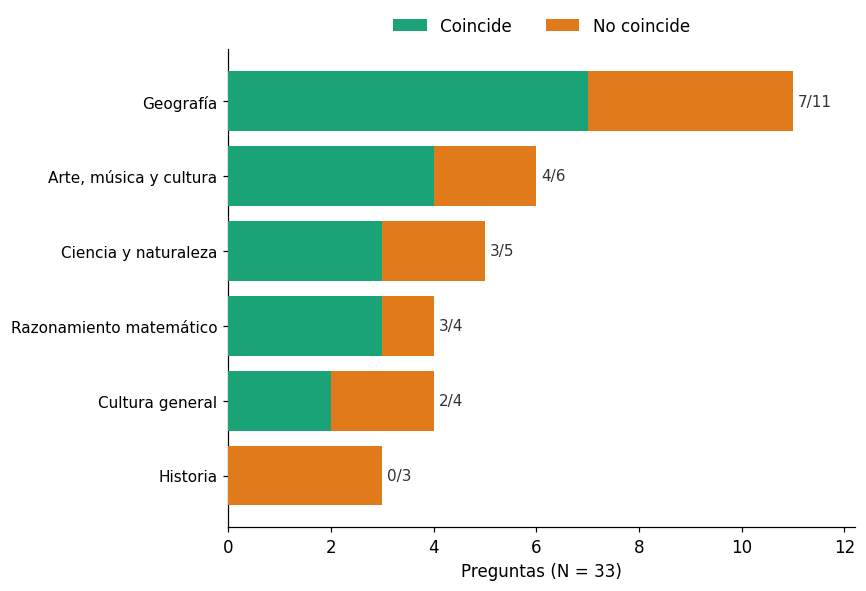

Coincidencia Rocha vs IA: 19/33 = 58%


In [4]:
# Aciertos/total por categoria, recalculados desde los veredictos del log (sesion optimista).
cats = [
    ("Geografía", 7, 11),
    ("Arte, música y cultura", 4, 6),
    ("Ciencia y naturaleza", 3, 5),
    ("Razonamiento matemático", 3, 4),
    ("Cultura general", 2, 4),
    ("Historia", 0, 3),
]
dfc = pd.DataFrame(cats, columns=["categoria","coincide","total"])
dfc["no_coincide"] = dfc["total"] - dfc["coincide"]
dfc = dfc.iloc[::-1].reset_index(drop=True)  # mayor arriba

fig, ax = plt.subplots(figsize=(8,5.5))
y = np.arange(len(dfc))
ax.barh(y, dfc["coincide"], color=VERDE, zorder=3, label="Coincide")
ax.barh(y, dfc["no_coincide"], left=dfc["coincide"], color=NARANJA, zorder=3, label="No coincide")
for i,(c,t) in enumerate(zip(dfc["coincide"], dfc["total"])):
    ax.text(t+0.1, i, f"{c}/{t}", va="center", fontsize=10, color="#333")
ax.set_yticks(y); ax.set_yticklabels(dfc["categoria"], fontsize=10)
co, to = dfc["coincide"].sum(), dfc["total"].sum()
ax.set_xlabel(f"Preguntas (N = {to})")
ax.legend(loc="upper center", bbox_to_anchor=(0.5,1.10), ncol=2, frameon=False, fontsize=11)
ax.set_xlim(0, dfc["total"].max()+1.2)
plt.tight_layout(); plt.show()
print(f"Coincidencia Rocha vs IA: {co}/{to} = {100*co/to:.0f}%")

## 3. Datos por turno

Se arma la tabla con el tiempo de cada etapa en cada pregunta. **STT, SER y TER
se toman directamente de `percepcion.csv`** (medidos en la Pi, por turno, por
separado). El resto (afectiva, LLM, tokens, emoción, movimiento) viene de
`turnos.csv`; TTS de `tts.csv`; la ventana FER se lee del log.

In [5]:
import re
# ventana FER por turno (del log, en orden de aparicion)
fer_vent = [float(m.group(1))*1000 for m in re.finditer(r"FER: \d+ cuadros en ([\d.]+) s", log)]
# TTS por turno (en orden; tts.csv no trae texto)
tts_vals = pd.to_numeric(tts["t_tts_ms"], errors="coerce").dropna().tolist()

n = min(N_PREGUNTAS, len(turnos), len(per_triv))
dft = pd.DataFrame({
    "pregunta": range(1, n+1),
    "STT": per_triv["t_stt_ms"].iloc[:n].values,
    "SER": per_triv["t_ser_ms"].iloc[:n].values,
    "TER": per_triv["t_ter_ms"].iloc[:n].values,
    "ida_vuelta": per_triv["ida_vuelta_ms"].iloc[:n].values,
    "afectiva": turnos["afectiva_ms"].iloc[:n].values,
    "LLM": turnos["t_llm_ms"].iloc[:n].values,
    "emocion": turnos["emocion"].iloc[:n].values,
    "movimiento": turnos["movimiento"].iloc[:n].values,
})
dft["TTS"] = [tts_vals[i] if i < len(tts_vals) else np.nan for i in range(n)]
dft["FER"] = [fer_vent[i] if i < len(fer_vent) else np.nan for i in range(n)]
# por nodo
dft["communication_node"] = dft[["STT","TTS"]].sum(axis=1, min_count=1)
dft["orchestrator_node"]  = dft[["afectiva","LLM"]].sum(axis=1, min_count=1)
dft["expression_faces_node"] = dft["FER"]
print(f"{len(dft)} turnos."); dft.head(10)

33 turnos.


,pregunta,STT,SER,TER,ida_vuelta,afectiva,LLM,emocion,movimiento,TTS,FER,communication_node,orchestrator_node,expression_faces_node
0,1,29.9,NaN,NaN,62.1,3700.0,489.0,felicidad_L1,ninguno,1523.6,87600.0,1553.5,4189.0,87600.0
1,2,94.2,274.5,24.7,471.4,3400.0,552.2,felicidad_L1,ninguno,1618.2,34900.0,1712.4,3952.2,34900.0
2,3,132.9,194.4,26.2,462.7,5400.0,379.4,felicidad_L1,ninguno,1429.6,10500.0,1562.5,5779.4,10500.0
3,4,106.9,304.2,17.2,502.2,13800.0,387.6,felicidad_L1,ninguno,1518.1,26800.0,1625.0,14187.6,26800.0
4,5,32.2,NaN,NaN,71.2,5700.0,379.5,felicidad_L1,ninguno,1012.8,15500.0,1045.0,6079.5,15500.0
5,6,51.2,174.0,17.9,314.5,6200.0,649.1,felicidad_L1,ninguno,1263.0,21100.0,1314.2,6849.1,21100.0
6,7,40.4,NaN,NaN,79.7,3900.0,556.1,felicidad_L1,ninguno,1270.6,239200.0,1311.0,4456.1,239200.0
7,8,89.5,235.4,20.3,415.4,6900.0,745.0,felicidad_L1,ninguno,1162.4,4800.0,1251.9,7645.0,4800.0
8,9,81.0,187.5,20.6,367.1,26300.0,441.8,felicidad_L1,ninguno,1171.6,24600.0,1252.6,26741.8,24600.0
9,10,92.3,222.1,22.9,401.6,12500.0,656.0,felicidad_L1,ninguno,2057.1,55700.0,2149.4,13156.0,55700.0


## 4. STT, SER y TER por turno — medidos en la Raspberry

Los tres tiempos de percepción del lenguaje/voz, capturados **por separado en la
propia Pi** (lo que pediste): **STT** (voz→texto), **SER** (emoción de la voz) y
**TER** (emoción del texto).

Como los tres tienen **escalas muy distintas** (el TER es ~15-25 ms, el SER
~200 ms y el STT ~80 ms), se grafican en **paneles separados, cada uno con su
propia escala**, para poder ver el procesamiento real de cada uno por pregunta.
Abajo va además la vista combinada con el viaje de ida y vuelta.

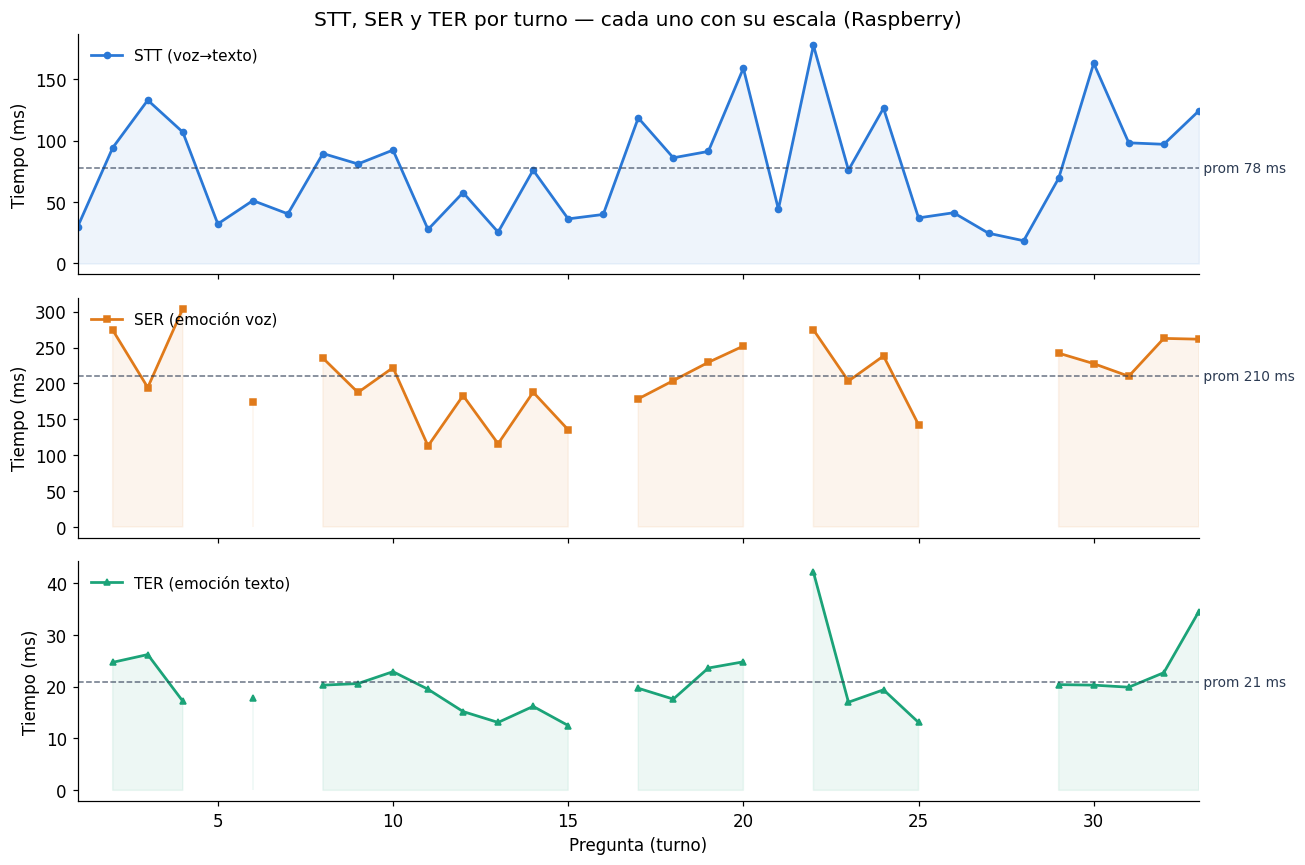

STT: 78 ms (min 18, max 178) | SER: 210 ms (min 113, max 304) | TER: 21 ms (min 12, max 42)


In [6]:
# Tres paneles, cada uno con su escala, para ver el detalle de cada etapa.
fig, axs = plt.subplots(3, 1, figsize=(12,8), sharex=True)
x = dft["pregunta"]
for ax, col, color, mk, nombre in [
    (axs[0], "STT", AZUL,    "o", "STT (voz→texto)"),
    (axs[1], "SER", NARANJA, "s", "SER (emoción voz)"),
    (axs[2], "TER", VERDE,   "^", "TER (emoción texto)"),
]:
    serie = dft[col]
    ax.plot(x, serie, color=color, lw=1.8, marker=mk, ms=4, label=nombre)
    prom = serie.mean()
    ax.axhline(prom, color=GRIS, ls="--", lw=1, alpha=0.7)
    ax.text(len(dft), prom, f" prom {prom:.0f} ms", va="center", fontsize=9, color=GRIS)
    ax.fill_between(x, 0, serie, color=color, alpha=0.08)
    ax.set_ylabel("Tiempo (ms)")
    ax.legend(loc="upper left", frameon=False, fontsize=10)
    ax.set_xlim(1, len(dft))
axs[2].set_xlabel("Pregunta (turno)")
axs[0].set_title("STT, SER y TER por turno — cada uno con su escala (Raspberry)")
plt.tight_layout(); plt.show()
print(f"STT: {dft['STT'].mean():.0f} ms (min {dft['STT'].min():.0f}, max {dft['STT'].max():.0f}) | "
      f"SER: {dft['SER'].mean():.0f} ms (min {dft['SER'].min():.0f}, max {dft['SER'].max():.0f}) | "
      f"TER: {dft['TER'].mean():.0f} ms (min {dft['TER'].min():.0f}, max {dft['TER'].max():.0f})")

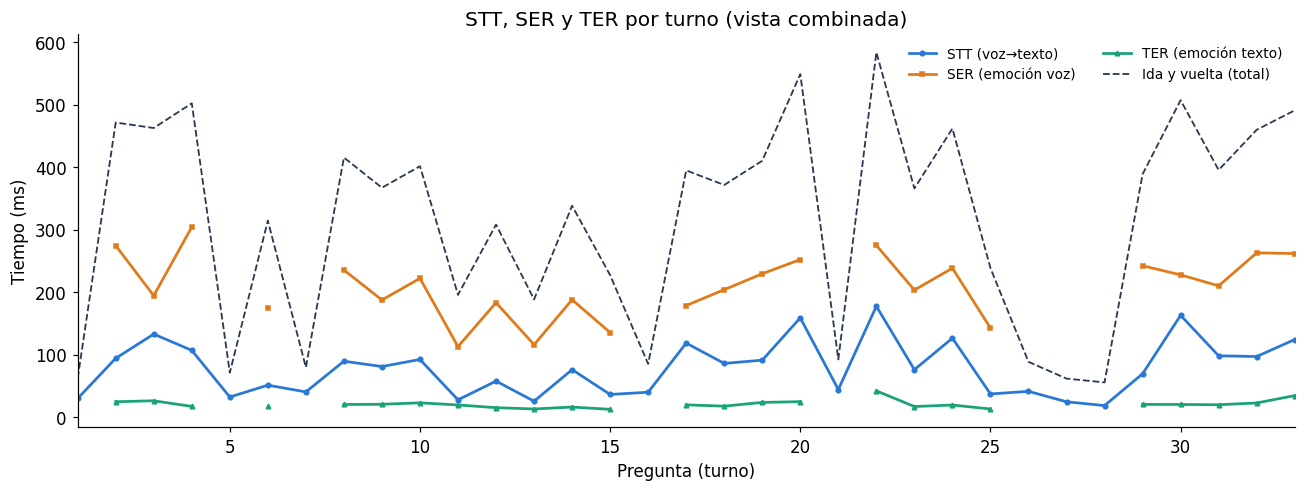

STT: 78 ms | SER: 210 ms | TER: 21 ms | Ida-vuelta: 315 ms (promedios)


In [7]:
# Vista combinada (misma escala) + viaje de ida y vuelta.
fig, ax = plt.subplots(figsize=(12,4.6))
x = dft["pregunta"]
ax.plot(x, dft["STT"], color=AZUL,    lw=1.8, marker="o", ms=3, label="STT (voz→texto)")
ax.plot(x, dft["SER"], color=NARANJA, lw=1.8, marker="s", ms=3, label="SER (emoción voz)")
ax.plot(x, dft["TER"], color=VERDE,   lw=1.8, marker="^", ms=3, label="TER (emoción texto)")
ax.plot(x, dft["ida_vuelta"], color=GRIS, lw=1.2, ls="--", label="Ida y vuelta (total)")
ax.set_xlabel("Pregunta (turno)"); ax.set_ylabel("Tiempo (ms)")
ax.set_xlim(1, len(dft))
ax.set_title("STT, SER y TER por turno (vista combinada)")
ax.legend(frameon=False, fontsize=9, ncol=2)
plt.tight_layout(); plt.show()
print(f"STT: {dft['STT'].mean():.0f} ms | SER: {dft['SER'].mean():.0f} ms | "
      f"TER: {dft['TER'].mean():.0f} ms | Ida-vuelta: {dft['ida_vuelta'].mean():.0f} ms (promedios)")

## 5. Línea de tiempo por nodo

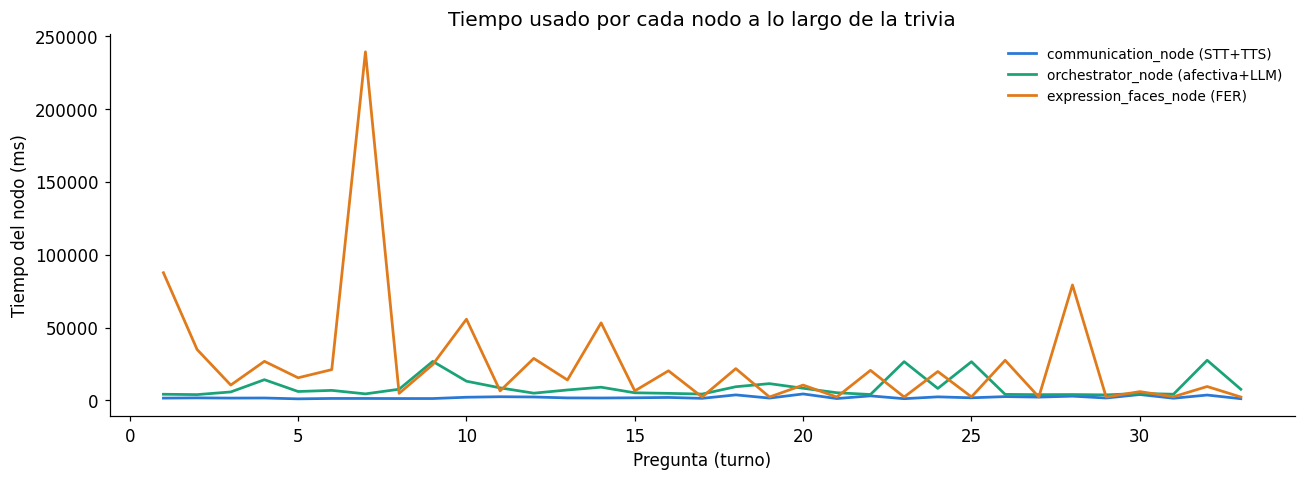

moving_control_node (carrito): no interviene en la trivia.


In [8]:
fig, ax = plt.subplots(figsize=(12,4.5))
x = dft["pregunta"]
ax.plot(x, dft["communication_node"], color=AZUL, lw=1.8, label="communication_node (STT+TTS)")
ax.plot(x, dft["orchestrator_node"], color=VERDE, lw=1.8, label="orchestrator_node (afectiva+LLM)")
ax.plot(x, dft["expression_faces_node"], color=NARANJA, lw=1.8, label="expression_faces_node (FER)")
ax.set_xlabel("Pregunta (turno)"); ax.set_ylabel("Tiempo del nodo (ms)")
ax.set_title("Tiempo usado por cada nodo a lo largo de la trivia")
ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()
print("moving_control_node (carrito): no interviene en la trivia.")

## 6. Latencia de respuesta por interacción (medida en la Raspberry)

Tiempo desde que el usuario termina de hablar hasta que Romeo responde, por cada
pregunta. Se mide en la Pi con los instantes del log (fin de transcripción →
inicio de la respuesta del asistente).

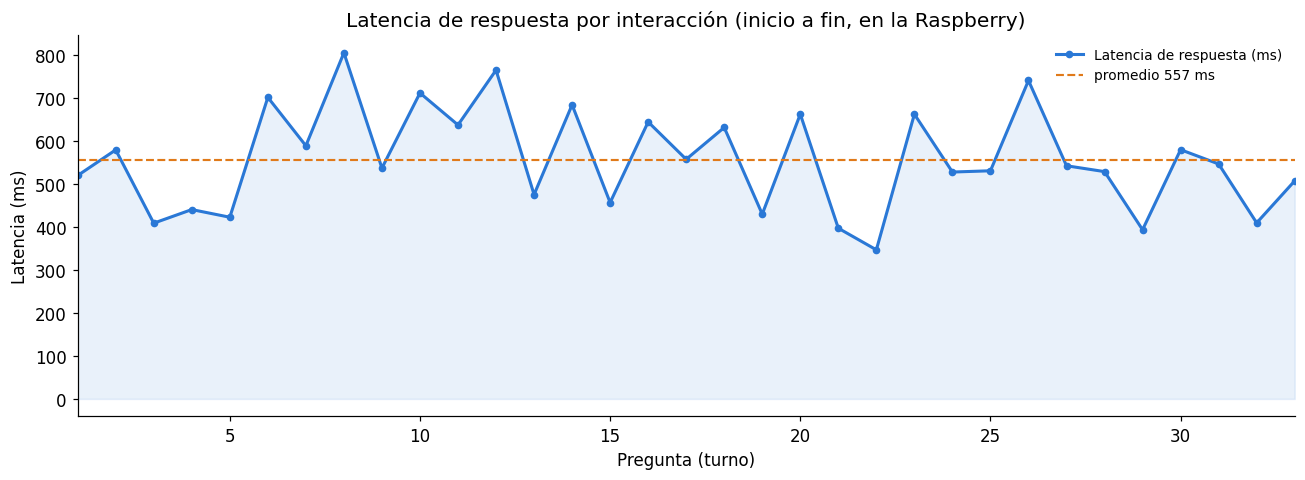

Latencia: promedio 557 ms, min 347, max 806 ms


In [9]:
latencias = []
t_mic = None
for ln in log.splitlines():
    m = re.search(r"\[(\d+\.\d+)\]", ln)
    if not m: continue
    ts = float(m.group(1))
    if "[mic] transcrito:" in ln:
        t_mic = ts
    elif "Asistente:" in ln and "Asistente [" not in ln and t_mic is not None and ts >= INICIO_TRIVIA:
        lat = (ts - t_mic) * 1000
        if 0 < lat < 30000:
            latencias.append(lat)
        t_mic = None
latencias = latencias[:N_PREGUNTAS]

fig, ax = plt.subplots(figsize=(12,4.5))
xx = range(1, len(latencias) + 1)
ax.plot(xx, latencias, color=AZUL, lw=2, marker="o", ms=4, label="Latencia de respuesta (ms)")
ax.axhline(np.mean(latencias), color=NARANJA, ls="--", lw=1.4,
           label=f"promedio {np.mean(latencias):.0f} ms")
ax.fill_between(xx, 0, latencias, color=AZUL, alpha=0.10)
ax.set_xlabel("Pregunta (turno)"); ax.set_ylabel("Latencia (ms)")
ax.set_xlim(1, len(latencias))
ax.set_title("Latencia de respuesta por interacción (inicio a fin, en la Raspberry)")
ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()
print(f"Latencia: promedio {np.mean(latencias):.0f} ms, min {min(latencias):.0f}, max {max(latencias):.0f} ms")

## 7. FER y capa afectiva por turno (medidos en la Raspberry)

La **ventana del FER** (duración de la percepción facial mientras el usuario
habla) y el bloque **percepción + capa afectiva** (PULSE+ROSE+AEB).

**La capa afectiva se calcula en los 33 turnos** (se quitó la regla que la
saltaba cuando las tres fuentes eran neutrales). Se muestran todos sin recorte:
el tiempo incluye la **espera de la ventana de cámara** antes de fusionar, por
eso los turnos donde el usuario tardó más en responder aparecen más altos.

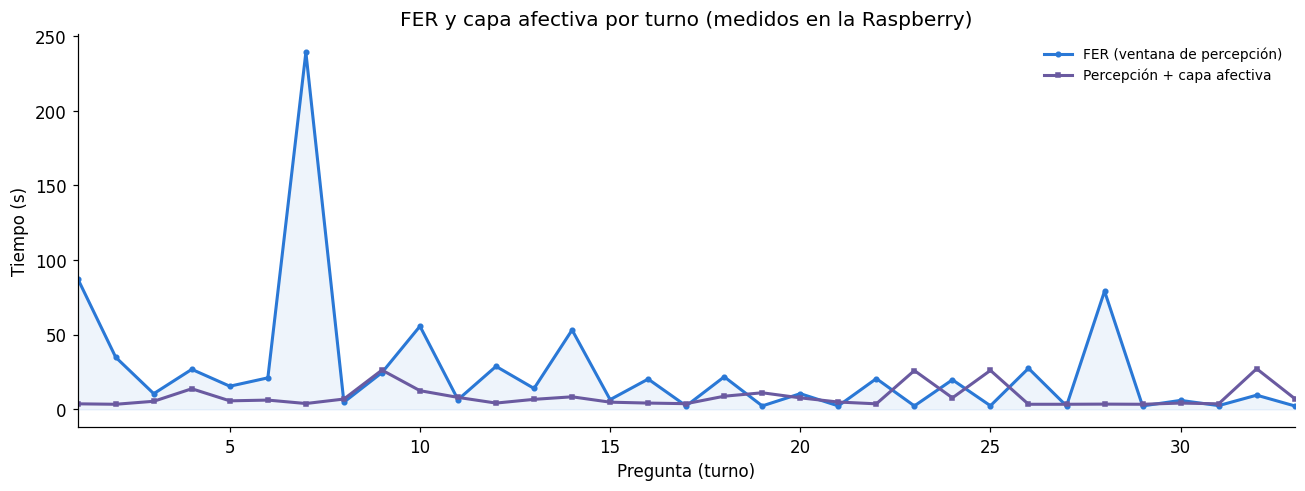

FER ventana: promedio 26.2 s | Percepción+afectiva: promedio 8.5 s


In [10]:
fig, ax = plt.subplots(figsize=(12,4.6))
x = dft["pregunta"]
fer_s = dft["FER"] / 1000.0
afe_s = dft["afectiva"] / 1000.0
ax.plot(x, fer_s, color=AZUL, lw=2, marker="o", ms=3, label="FER (ventana de percepción)")
ax.plot(x, afe_s, color=MORADO, lw=2, marker="s", ms=3, label="Percepción + capa afectiva")
ax.fill_between(x, 0, fer_s, color=AZUL, alpha=0.08)
ax.set_xlabel("Pregunta (turno)"); ax.set_ylabel("Tiempo (s)")
ax.set_xlim(1, len(dft))
ax.set_title("FER y capa afectiva por turno (medidos en la Raspberry)")
ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()
print(f"FER ventana: promedio {fer_s.mean():.1f} s | Percepción+afectiva: promedio {afe_s.mean():.1f} s")

## 8. Línea de tiempo — LLM y TTS durante la trivia

Tiempo del modelo de lenguaje (LLM gemma3:4b) y de la síntesis de voz (TTS) por turno.

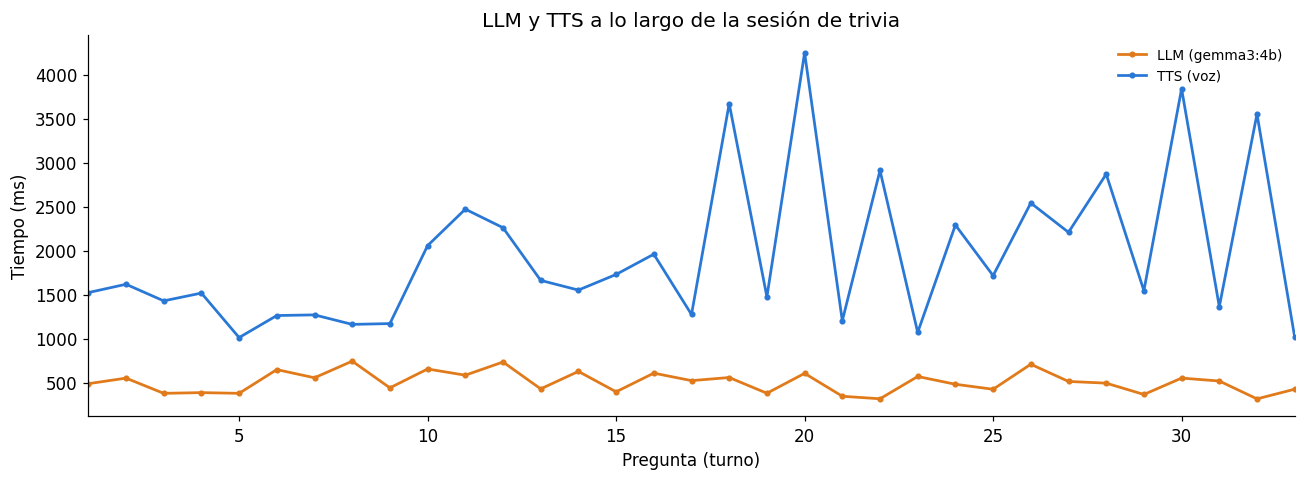

LLM: promedio 507 ms | TTS: promedio 1953 ms


In [11]:
fig, ax = plt.subplots(figsize=(12,4.5))
x = dft["pregunta"]
ax.plot(x, dft["LLM"], color=NARANJA, lw=1.8, marker="o", ms=3, label="LLM (gemma3:4b)")
ax.plot(x, dft["TTS"], color=AZUL, lw=1.8, marker="o", ms=3, label="TTS (voz)")
ax.set_xlabel("Pregunta (turno)"); ax.set_ylabel("Tiempo (ms)")
ax.set_xlim(1, len(dft))
ax.set_title("LLM y TTS a lo largo de la sesión de trivia")
ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()
print(f"LLM: promedio {dft['LLM'].mean():.0f} ms | TTS: promedio {dft['TTS'].mean():.0f} ms")

## 9. Estado emocional de Romeo durante la trivia (AEB)

Emoción y nivel que Romeo mostró en cada turno (su estado afectivo real, no una
cara por defecto de acertó/falló). Con el perfil **optimista** su base lo mantiene
en felicidad aunque el usuario esté neutral.

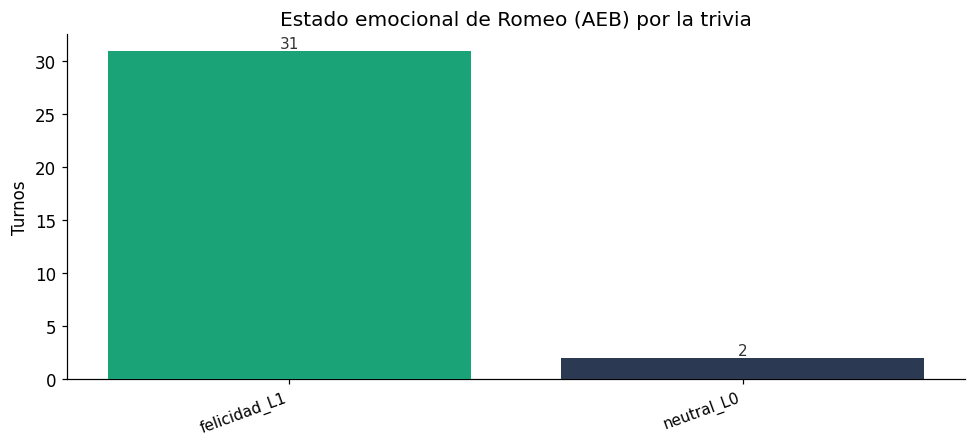

Emociones mostradas:
emocion
felicidad_L1    31
neutral_L0       2

Movimientos:
movimiento
ninguno    33


In [12]:
conteo = dft["emocion"].value_counts()
fig, ax = plt.subplots(figsize=(9,4.2))
colores = {"felicidad_L1":VERDE, "felicidad_L2":"#15c08a", "felicidad_L3":"#0e8f66",
           "neutral_L0":GRIS, "tristeza_L1":AZUL, "enojo_L1":ROJO}
cs = [colores.get(e, MORADO) for e in conteo.index]
ax.bar(range(len(conteo)), conteo.values, color=cs, zorder=3)
ax.set_xticks(range(len(conteo))); ax.set_xticklabels(conteo.index, rotation=20, ha="right", fontsize=10)
for i,v in enumerate(conteo.values):
    ax.text(i, v+0.2, str(v), ha="center", fontsize=10, color="#333")
ax.set_ylabel("Turnos"); ax.set_title("Estado emocional de Romeo (AEB) por la trivia")
plt.tight_layout(); plt.show()
print("Emociones mostradas:"); print(conteo.to_string())
mov = dft["movimiento"].value_counts()
print("\nMovimientos:"); print(mov.to_string())

## 10. Recursos de la Raspberry Pi (de inicio a fin)

CPU total, proceso de cámara (FER), **temperatura real** y RAM durante la sesión.
En esta corrida la temperatura **sí se capturó** (lectura de `thermal_zone0`).

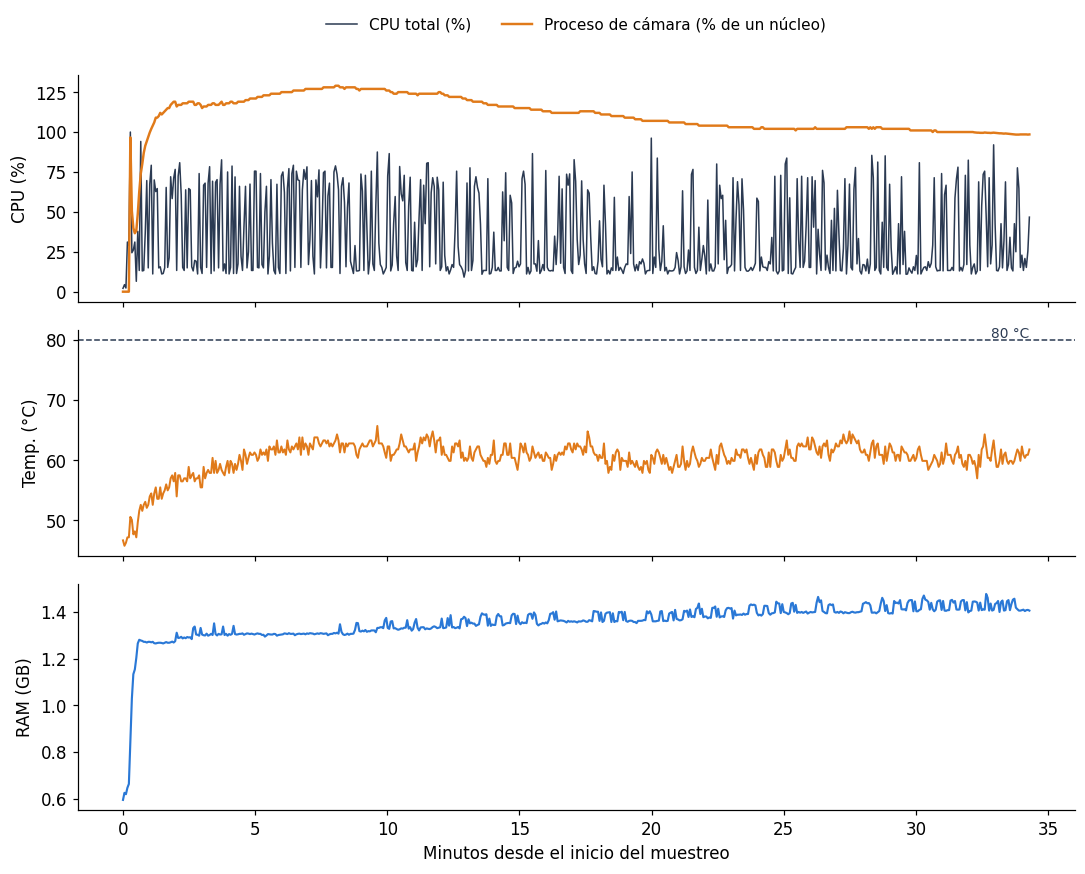

Recursos:
  CPU total:  mediana 17.4%  max 100.0%
  CPU camara: mediana 110.0%  max 129.0%
  Temp:       mediana 60.9°C  max 65.7°C
  RAM usada:  mediana 1396 MB  max 1512 MB


In [13]:
ram_gb = sis["ram_usada_mb"] / 1024

fig, axs = plt.subplots(3, 1, figsize=(10,8), sharex=True)
# (1) CPU total + camara
axs[0].plot(sis["min"], sis["cpu_total_pct"], color=GRIS, lw=1, label="CPU total (%)")
axs[0].plot(sis["min"], sis["cpu_camara_pct"], color=NARANJA, lw=1.6, label="Proceso de cámara (% de un núcleo)")
axs[0].set_ylabel("CPU (%)")
axs[0].legend(loc="upper center", bbox_to_anchor=(0.5,1.32), ncol=2, frameon=False, fontsize=10)
# (2) Temperatura real
axs[1].plot(sis["min"], sis["temp_c"], color=NARANJA, lw=1.3)
axs[1].axhline(80, color=GRIS, ls="--", lw=1)
axs[1].text(sis["min"].max(), 80.4, "80 °C", ha="right", fontsize=9, color=GRIS)
axs[1].set_ylabel("Temp. (°C)")
# (3) RAM
axs[2].plot(sis["min"], ram_gb, color=AZUL, lw=1.4)
axs[2].set_ylabel("RAM (GB)")
axs[2].set_xlabel("Minutos desde el inicio del muestreo")
plt.tight_layout(); plt.show()

print("Recursos:")
print(f"  CPU total:  mediana {sis['cpu_total_pct'].median():.1f}%  max {sis['cpu_total_pct'].max():.1f}%")
print(f"  CPU camara: mediana {sis['cpu_camara_pct'].median():.1f}%  max {sis['cpu_camara_pct'].max():.1f}%")
print(f"  Temp:       mediana {sis['temp_c'].median():.1f}°C  max {sis['temp_c'].max():.1f}°C")
print(f"  RAM usada:  mediana {sis['ram_usada_mb'].median():.0f} MB  max {sis['ram_usada_mb'].max():.0f} MB")

## 11. Tabla resumen (trivia)

In [14]:
def prom1(s):
    s = pd.to_numeric(s, errors="coerce").dropna()
    return round(s.mean(),1) if len(s) else np.nan

tabla = []
for nombre, serie, unidad, nodo in [
    ("STT (voz→texto)", dft["STT"], "ms", "communication / Pi"),
    ("SER (emoción voz)", dft["SER"], "ms", "communication / Pi"),
    ("TER (emoción texto)", dft["TER"], "ms", "communication / Pi"),
    ("Ida-vuelta percepción", dft["ida_vuelta"], "ms", "Pi ↔ servidor"),
    ("Afectiva PULSE+ROSE+AEB", dft["afectiva"], "ms", "orchestrator / Pi"),
    ("Respuesta LLM", dft["t_llm_ms"] if "t_llm_ms" in dft else dft["LLM"], "ms", "orchestrator / Pi→PC"),
    ("Síntesis TTS", dft["TTS"], "ms", "communication / PC"),
    ("Ventana FER", dft["FER"], "ms", "expression / Pi"),
    ("Tokens de salida", turnos["tokens_salida"], "tokens", "orchestrator"),
    ("CPU total Pi", sis["cpu_total_pct"], "%", "Raspberry"),
    ("CPU cámara/FER", sis["cpu_camara_pct"], "%", "expression"),
    ("Temperatura Pi", sis["temp_c"], "°C", "Raspberry"),
    ("RAM usada Pi", sis["ram_usada_mb"], "MB", "Raspberry"),
]:
    tabla.append([nombre, prom1(serie), unidad, nodo])
df = pd.DataFrame(tabla, columns=["Indicador","Promedio","Unidad","Nodo / máquina"])
print("Coincidencia Rocha vs IA: 19/33 = 58%\n")
df

Coincidencia Rocha vs IA: 19/33 = 58%



,Indicador,Promedio,Unidad,Nodo / máquina
0,STT (voz→texto),77.7,ms,communication / Pi
1,SER (emoción voz),210.2,ms,communication / Pi
2,TER (emoción texto),20.9,ms,communication / Pi
3,Ida-vuelta percepción,315.4,ms,Pi ↔ servidor
4,Afectiva PULSE+ROSE+AEB,8481.8,ms,orchestrator / Pi
5,Respuesta LLM,507.1,ms,orchestrator / Pi→PC
6,Síntesis TTS,1953.3,ms,communication / PC
7,Ventana FER,26239.4,ms,expression / Pi
8,Tokens de salida,36.0,tokens,orchestrator
9,CPU total Pi,34.0,%,Raspberry
